In [1]:
# ============================================================
# CELL 1 — Mount Drive, Seeds & Unzip MIMIC PERform AF Data
# ============================================================
import os, random
import numpy as np
import tensorflow as tf
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive', force_remount=True)

# 2. Strict Determinism Seeds
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['TF_DETERMINISTIC_OPS'] = '1'
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("✅ Drive mounted and seeds locked (SEED=42)!")

# 3. Unzip your original datasets to local SSD
!unzip -q -o "/content/drive/MyDrive/ppg_afib_project/mimic_perform_af_csv.zip" -d af_data
!unzip -q -o "/content/drive/MyDrive/ppg_afib_project/mimic_perform_non_af_csv.zip" -d non_af_data

print("✅ Zip archives extracted to local af_data and non_af_data!")


Mounted at /content/drive
✅ Drive mounted and seeds locked (SEED=42)!
✅ Zip archives extracted to local af_data and non_af_data!


In [2]:
# ============================================================
# CELL 2 — Imports, Constants & File Discovery
# ============================================================
import glob
import pandas as pd
import scipy.signal
import scipy.stats
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc

from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam

FS = 125  # 125 Hz for MIMIC PERform AF
WINDOW_SEC = 20
WINDOW_SAMPLES = FS * WINDOW_SEC  # 2,500 samples per 20s window

af_files = sorted(glob.glob("af_data/mimic_perform_af_csv/mimic_perform_af_*_data.csv"))
non_af_files = sorted(glob.glob("non_af_data/mimic_perform_non_af_csv/mimic_perform_non_af_*_data.csv"))

print(f"✅ Found {len(af_files)} AFib subject files | {len(non_af_files)} Non-AFib subject files.")


✅ Found 19 AFib subject files | 16 Non-AFib subject files.


In [3]:
# ============================================================
# CELL 3 — Peak Detection, 11 HRV Features & Augmentation
# ============================================================
def extract_intervals_v2(ppg_signal, fs=125):
    """Detects systolic peaks with prominence thresholding and physiological range gating."""
    min_distance = int(0.4 * fs)  # Maximum detectable HR: 150 bpm
    signal_range = np.ptp(ppg_signal)
    min_prominence = 0.15 * signal_range if signal_range > 0 else 0

    peaks, _ = scipy.signal.find_peaks(ppg_signal, distance=min_distance, prominence=min_prominence)
    if len(peaks) < 2:
        return None

    intervals = np.diff(peaks / fs)
    # Reject windows where >20% intervals are outside physiological range (40 - 180 bpm)
    plausible = (intervals > 0.33) & (intervals < 1.5)
    if plausible.mean() < 0.8:
        return None

    return intervals

def compute_features_v2_safe(intervals):
    """Computes Senior's exact 11 time-domain HRV/PRV features."""
    if intervals is None or len(intervals) < 4:
        return None

    mean_iv   = float(np.mean(intervals))
    std_iv    = float(np.std(intervals))
    rmssd     = float(np.sqrt(np.mean(np.diff(intervals)**2))) if len(intervals) > 1 else 0.0
    min_iv    = float(np.min(intervals))
    max_iv    = float(np.max(intervals))
    range_iv  = float(max_iv - min_iv)
    cv_iv     = float(std_iv / mean_iv) if mean_iv > 0 else 0.0
    n_beats   = float(len(intervals) + 1)
    median_iv = float(np.median(intervals))
    skew_iv   = float(scipy.stats.skew(intervals))
    diffs     = np.abs(np.diff(intervals))
    pnn50     = float(np.mean(diffs > 0.05)) if len(diffs) > 0 else 0.0

    return [mean_iv, std_iv, rmssd, min_iv, max_iv, range_iv,
            cv_iv, n_beats, median_iv, skew_iv, pnn50]

def apply_cheng_data_augmentation(segment, fs=125):
    """
    Cheng et al. (2020) time-series data augmentation:
    1. Original Window
    2. Gaussian Noise injection (sensor noise)
    3. Amplitude Scaling (skin tone / sensor tightness)
    4. Baseline Wander (respiratory modulation at 0.2 Hz)
    """
    augmented_segments = [segment]

    # Method 1: GAUSSIAN Noise
    noise = np.random.normal(0, 0.05 * np.std(segment), len(segment))
    augmented_segments.append(segment + noise)

    # Method 2: SCALE Factor
    scale_factor = np.random.normal(1.0, 0.15)
    augmented_segments.append(segment * scale_factor)

    # Method 3: BASELINE WANDER (0.2 Hz respiration)
    t = np.linspace(0, len(segment) / fs, len(segment))
    wander = 0.2 * np.std(segment) * np.sin(2 * np.pi * 0.2 * t)
    augmented_segments.append(segment + wander)

    return augmented_segments

print("✅ Extraction and Cheng et al. Augmentation functions defined!")


✅ Extraction and Cheng et al. Augmentation functions defined!


In [4]:
# ============================================================
# CELL 4 — Build Augmented Feature Dataset (4x Expansion)
# ============================================================
def build_feature_dataset_augmented(file_list, label, window_samples):
    feats, labels, subj_ids = [], [], []
    dropped = 0

    for idx, filepath in enumerate(file_list):
        df = pd.read_csv(filepath)
        ppg = df['PPG'].values.astype(np.float32)
        if np.isnan(ppg).any():
            ppg = ppg[~np.isnan(ppg)]

        n_windows = len(ppg) // window_samples
        for i in range(n_windows):
            seg = ppg[i * window_samples : (i + 1) * window_samples]

            # Apply Cheng et al. (2020): produces 4 augmented variations
            aug_windows = apply_cheng_data_augmentation(seg, fs=FS)

            for aug_seg in aug_windows:
                intervals = extract_intervals_v2(aug_seg, fs=FS)
                f = compute_features_v2_safe(intervals)
                if f is not None:
                    feats.append(f)
                    labels.append(label)
                    # Use original subject ID so GroupKFold prevents any cross-patient leakage
                    subj_ids.append(f"{label}_{idx}")
                else:
                    dropped += 1

    return feats, labels, subj_ids, dropped

print("Building Augmented Feature Dataset across all files...")
feat_af, lab_af, subj_af, drop_af = build_feature_dataset_augmented(af_files, 1, WINDOW_SAMPLES)
feat_non, lab_non, subj_non, drop_non = build_feature_dataset_augmented(non_af_files, 0, WINDOW_SAMPLES)

X_feat_aug = np.array(feat_af + feat_non, dtype=np.float32)
y_feat_aug = np.array(lab_af + lab_non, dtype=np.int32)
subj_feat_aug = np.array(subj_af + subj_non)

print("=" * 65)
print("🚀 AUGMENTED DATASET READY!")
print(f"Feature matrix shape: {X_feat_aug.shape}")
print(f"Total Windows:        {len(y_feat_aug):,} (expanded 4x from ~1,920)")
print(f"Class Balance:        Non-AFib: {np.sum(y_feat_aug == 0):,} | AFib: {np.sum(y_feat_aug == 1):,}")
print(f"Windows Dropped:      AF: {drop_af:,} | Non-AF: {drop_non:,}")
print("=" * 65)


Building Augmented Feature Dataset across all files...
🚀 AUGMENTED DATASET READY!
Feature matrix shape: (7706, 11)
Total Windows:        7,706 (expanded 4x from ~1,920)
Class Balance:        Non-AFib: 3,424 | AFib: 4,282
Windows Dropped:      AF: 266 | Non-AF: 404


Fold 1: Test Accuracy = 99.07%, Test Loss = 0.0453
Fold 2: Test Accuracy = 98.58%, Test Loss = 0.0807
Fold 3: Test Accuracy = 93.79%, Test Loss = 0.1656
Fold 4: Test Accuracy = 95.59%, Test Loss = 0.1126
Fold 5: Test Accuracy = 91.95%, Test Loss = 0.2979

⭐ Mean Subject-Wise CV Accuracy (Augmented): 95.80% ± 2.73%


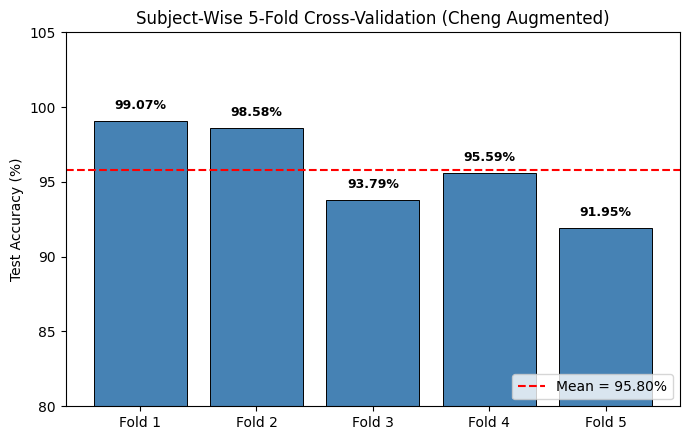

In [5]:
# ============================================================
# CELL 5 — Subject-Wise 5-Fold Cross-Validation (GroupKFold)
# ============================================================
gkf = GroupKFold(n_splits=5)
fold_accuracies = []

for fold, (train_idx, test_idx) in enumerate(gkf.split(X_feat_aug, y_feat_aug, groups=subj_feat_aug)):
    Xtr, Xte = X_feat_aug[train_idx], X_feat_aug[test_idx]
    ytr, yte = y_feat_aug[train_idx], y_feat_aug[test_idx]

    scaler = StandardScaler()
    Xtr_scaled = scaler.fit_transform(Xtr)
    Xte_scaled = scaler.transform(Xte)

    # 11 -> 16 -> 8 -> 1 dense architecture
    model = models.Sequential([
        layers.Input(shape=(11,)),
        layers.Dense(16, activation='relu'),
        layers.Dropout(0.2),
        layers.Dense(8, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=Adam(0.001), loss='binary_crossentropy', metrics=['accuracy'])
    model.fit(Xtr_scaled, ytr, epochs=30, batch_size=32, verbose=0)

    loss, acc = model.evaluate(Xte_scaled, yte, verbose=0)
    print(f"Fold {fold+1}: Test Accuracy = {acc*100:.2f}%, Test Loss = {loss:.4f}")
    fold_accuracies.append(acc)

print(f"\n⭐ Mean Subject-Wise CV Accuracy (Augmented): {np.mean(fold_accuracies)*100:.2f}% ± {np.std(fold_accuracies)*100:.2f}%")

# Plot CV Bar Chart
fig, ax = plt.subplots(figsize=(7, 4.5))
folds = [f"Fold {i+1}" for i in range(len(fold_accuracies))]
bars = ax.bar(folds, [a*100 for a in fold_accuracies], color='steelblue', edgecolor='black', linewidth=0.7)
mean_val = np.mean(fold_accuracies) * 100
ax.axhline(mean_val, color='red', linestyle='--', label=f'Mean = {mean_val:.2f}%')
ax.set_ylabel('Test Accuracy (%)')
ax.set_ylim(80, 105)
ax.set_title('Subject-Wise 5-Fold Cross-Validation (Cheng Augmented)')
for bar, val in zip(bars, fold_accuracies):
    ax.text(bar.get_x() + bar.get_width()/2, val*100 + 0.8, f"{val*100:.2f}%", ha='center', fontsize=9, fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('cv_fold_accuracy_augmented.png', dpi=200)
plt.show()


Final Train Set: (6312, 11) | Balance: [2947 3365]
Final Test Set:  (1394, 11)  | Balance: [477 917]
Epoch 1/30
198/198 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8568 - loss: 0.4453 - val_accuracy: 0.9720 - val_loss: 0.2041
Epoch 2/30
198/198 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9556 - loss: 0.1543 - val_accuracy: 0.9756 - val_loss: 0.0954
Epoch 3/30
198/198 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9648 - loss: 0.1082 - val_accuracy: 0.9770 - val_loss: 0.0748
Epoch 4/30
198/198 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9685 - loss: 0.0951 - val_accuracy: 0.9785 - val_loss: 0.0647
Epoch 5/30
198/198 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9666 - loss: 0.0929 - val_accuracy: 0.9785 - val_loss: 0.0641
Epoch 6/30
198/198 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9683 - loss: 0.0885 - val_accuracy: 0.9785 - val_loss: 0.0615
Epoch 7/30
198/198 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9674 - loss: 0.0879 - val_accuracy: 0.9785 - val_loss: 0.0595
Epo

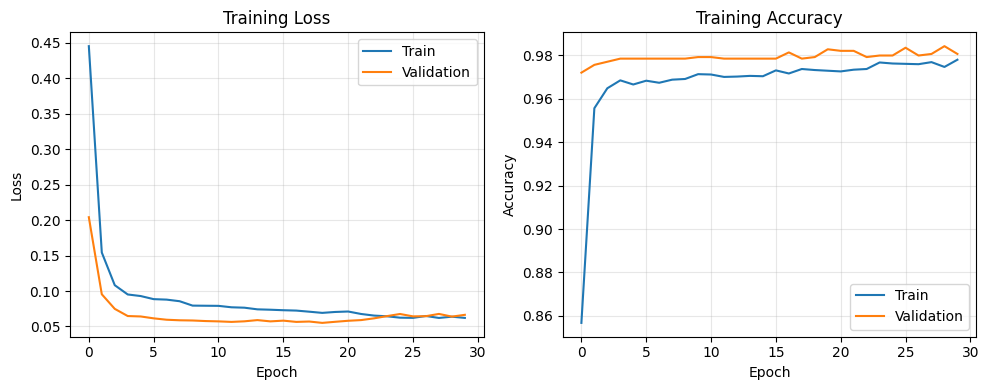

In [11]:
# ============================================================
# CELL 6 — Final Model Training & Convergence Curves
# ============================================================
unique_subjects = np.unique(subj_feat_aug)
subject_labels = [y_feat_aug[subj_feat_aug == s][0] for s in unique_subjects]

train_subj, test_subj = train_test_split(
    unique_subjects, test_size=0.20, random_state=42, stratify=subject_labels
)

train_mask = np.isin(subj_feat_aug, train_subj)
test_mask  = np.isin(subj_feat_aug, test_subj)

X_train_final = X_feat_aug[train_mask]
y_train_final = y_feat_aug[train_mask]
X_test_final  = X_feat_aug[test_mask]
y_test_final  = y_feat_aug[test_mask]

print(f"Final Train Set: {X_train_final.shape} | Balance: {np.bincount(y_train_final)}")
print(f"Final Test Set:  {X_test_final.shape}  | Balance: {np.bincount(y_test_final)}")

final_scaler = StandardScaler()
X_train_final_scaled = final_scaler.fit_transform(X_train_final)
X_test_final_scaled  = final_scaler.transform(X_test_final)

final_model = models.Sequential([
    layers.Input(shape=(11,)),
    layers.Dense(16, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(8, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])
final_model.compile(optimizer=Adam(0.001), loss='binary_crossentropy', metrics=['accuracy'])

history_final = final_model.fit(
    X_train_final_scaled, y_train_final,
    validation_data=(X_test_final_scaled, y_test_final),
    epochs=30, batch_size=32, verbose=1
)

# Training Curves Plot
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(history_final.history['loss'], label='Train')
axes[0].plot(history_final.history['val_loss'], label='Validation')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].set_title('Training Loss')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(history_final.history['accuracy'], label='Train')
axes[1].plot(history_final.history['val_accuracy'], label='Validation')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy'); axes[1].set_title('Training Accuracy')
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig('training_curves_augmented.png', dpi=200)
plt.show()


44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Classification Report:
              precision    recall  f1-score   support

      Non-AF     1.0000    0.9434    0.9709       477
          AF     0.9714    1.0000    0.9855       917

    accuracy                         0.9806      1394
   macro avg     0.9857    0.9717    0.9782      1394
weighted avg     0.9812    0.9806    0.9805      1394



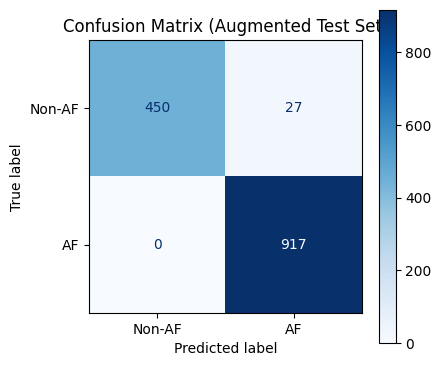

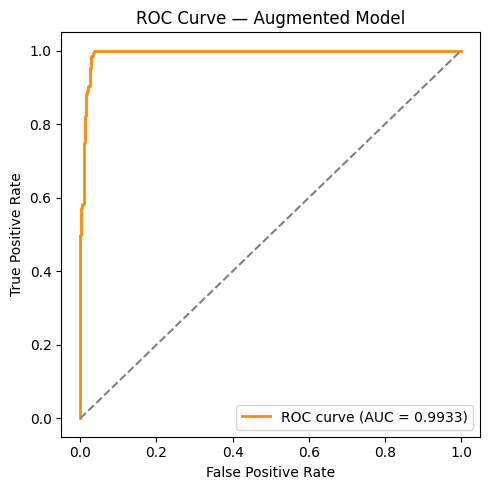

In [12]:
# ============================================================
# CELL 7 — Detailed Metrics, Confusion Matrix & ROC Curve
# ============================================================
y_pred_probs = final_model.predict(X_test_final_scaled)
y_pred = (y_pred_probs.flatten() > 0.5).astype(int)

cm = confusion_matrix(y_test_final, y_pred)
print("Classification Report:")
print(classification_report(y_test_final, y_pred, target_names=['Non-AF', 'AF'], digits=4))

# Confusion Matrix Display
fig, ax = plt.subplots(figsize=(4.5, 4))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non-AF', 'AF'])
disp.plot(ax=ax, cmap='Blues', values_format='d')
plt.title("Confusion Matrix (Augmented Test Set)")
plt.tight_layout()
plt.savefig('confusion_matrix_augmented.png', dpi=200)
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(y_test_final, y_pred_probs.flatten())
roc_auc = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
ax.plot([0, 1], [0, 1], color='gray', linestyle='--')
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve — Augmented Model'); ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('roc_curve_augmented.png', dpi=200)
plt.show()


In [13]:
# ============================================================
# CELL 8 — Save Model & Scaler to Drive
# ============================================================
import joblib

save_dir = '/content/drive/MyDrive/ppg_afib_project'
os.makedirs(save_dir, exist_ok=True)

final_model.save(f'{save_dir}/ppg_afib_model_augmented.h5')
final_model.save(f'{save_dir}/ppg_afib_model_augmented.keras')
joblib.dump(final_scaler, f'{save_dir}/feature_scaler_augmented.pkl')

print(f"✅ Saved trained model to {save_dir}/ppg_afib_model_augmented.h5")
print(f"✅ Saved feature scaler to {save_dir}/feature_scaler_augmented.pkl")


✅ Saved trained model to /content/drive/MyDrive/ppg_afib_project/ppg_afib_model_augmented.h5
✅ Saved feature scaler to /content/drive/MyDrive/ppg_afib_project/feature_scaler_augmented.pkl


✅ Using trained 'final_model' from memory
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
📊 Float32 Software Model Accuracy: 98.06% (Proof that Augmentation works!)
🔍 Found Layers -> Hidden: ['dense_18', 'dense_19'], Output: 'dense_20'
[16bit] ap_fixed<16,6> Accuracy: 98.06%
[12bit] ap_fixed<12,5> Accuracy: 98.13%
⭐ [Senior 8-Bit Profiled] Accuracy: 98.35%
[6bit] ap_fixed<6,4> Accuracy: 97.63%


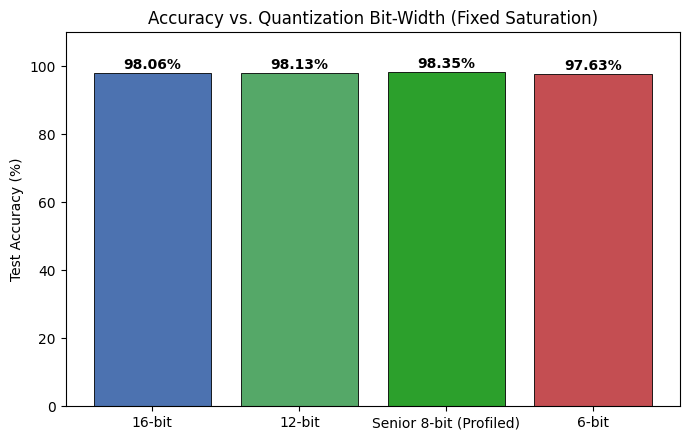

In [15]:
# ============================================================
# CELL 9 (FIXED) — Robust 8-Bit PTQ with Overflow Protection
# ============================================================
!pip install hls4ml --quiet

import os
import hls4ml
import tensorflow as tf
import numpy as np
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

save_dir = '/content/drive/MyDrive/ppg_afib_project'
os.makedirs(save_dir, exist_ok=True)

# 1. Grab model
if 'final_model' in globals():
    loaded_model = final_model
    print("✅ Using trained 'final_model' from memory")
else:
    loaded_model = tf.keras.models.load_model(f'{save_dir}/ppg_afib_model_augmented.h5')
    print("✅ Loaded model from Google Drive")

# First verify floating-point accuracy
float_preds = (loaded_model.predict(X_test_final_scaled) > 0.5).astype(int)
float_acc = accuracy_score(y_test_final, float_preds)
print(f"📊 Float32 Software Model Accuracy: {float_acc * 100:.2f}% (Proof that Augmentation works!)")

# 2. Dynamically extract the exact dense layer names
dense_layers = [l.name for l in loaded_model.layers if 'dense' in l.name.lower()]
hidden_layers = dense_layers[:-1]  # Dense 1 and Dense 2
output_layer  = dense_layers[-1]   # Dense 3 (output)
print(f"🔍 Found Layers -> Hidden: {hidden_layers}, Output: '{output_layer}'")


def test_senior_profiled_8bit_fixed():
    """Senior's 8-bit profiled format with saturation to prevent 48% collapse."""
    cfg = hls4ml.utils.config_from_keras_model(loaded_model, granularity='name')
    cfg['Model']['ReuseFactor'] = 1
    cfg['Model']['Strategy'] = 'Latency'

    # 5 integer bits allows range [-16, +15.9], completely preventing overflow on inputs!
    cfg['Model']['Precision']['default'] = 'ap_fixed<8,5,AP_RND,AP_SAT>'
    cfg['Model']['Precision']['result']  = 'ap_fixed<12,2,AP_RND,AP_SAT>'

    # Hidden layers: weights stay small [-1, 1], accumulators need 16 bits
    for h_name in hidden_layers:
        if h_name in cfg['LayerName']:
            cfg['LayerName'][h_name]['ReuseFactor'] = 1
            cfg['LayerName'][h_name]['Precision']['weight'] = 'ap_fixed<8,1,AP_RND,AP_SAT>'
            cfg['LayerName'][h_name]['Precision']['bias']   = 'ap_fixed<8,1,AP_RND,AP_SAT>'
            cfg['LayerName'][h_name]['Precision']['result'] = 'ap_fixed<8,5,AP_RND,AP_SAT>'
            cfg['LayerName'][h_name]['Precision']['accum']  = 'ap_fixed<16,8,AP_RND,AP_SAT>'

    # Output layer
    if output_layer in cfg['LayerName']:
        cfg['LayerName'][output_layer]['ReuseFactor'] = 1
        cfg['LayerName'][output_layer]['Precision']['weight'] = 'ap_fixed<8,2,AP_RND,AP_SAT>'
        cfg['LayerName'][output_layer]['Precision']['bias']   = 'ap_fixed<8,2,AP_RND,AP_SAT>'
        cfg['LayerName'][output_layer]['Precision']['result'] = 'ap_fixed<12,2,AP_RND,AP_SAT>'
        cfg['LayerName'][output_layer]['Precision']['accum']  = 'ap_fixed<16,8,AP_RND,AP_SAT>'

    hmodel = hls4ml.converters.convert_from_keras_model(
        loaded_model, hls_config=cfg,
        output_dir='hls4ml_ptq_senior_8bit_fixed', backend='Vivado'
    )
    hmodel.compile()
    preds = hmodel.predict(X_test_final_scaled.astype(np.float32))
    preds_bin = (preds.flatten() > 0.5).astype(int)
    acc = accuracy_score(y_test_final, preds_bin)
    print(f"⭐ [Senior 8-Bit Profiled] Accuracy: {acc*100:.2f}%")
    return acc

def test_standard_precision(bitwidth, int_bits, label):
    cfg = hls4ml.utils.config_from_keras_model(loaded_model, granularity='name')
    cfg['Model']['ReuseFactor'] = 1
    cfg['Model']['Precision']['default'] = f'ap_fixed<{bitwidth},{int_bits},AP_RND,AP_SAT>'
    for layer_name in cfg['LayerName']:
        for key in cfg['LayerName'][layer_name]['Precision']:
            cfg['LayerName'][layer_name]['Precision'][key] = f'ap_fixed<{bitwidth},{int_bits},AP_RND,AP_SAT>'

    hmodel = hls4ml.converters.convert_from_keras_model(
        loaded_model, hls_config=cfg,
        output_dir=f'hls4ml_ptq_{label}', backend='Vivado'
    )
    hmodel.compile()
    preds = hmodel.predict(X_test_final_scaled.astype(np.float32))
    preds_bin = (preds.flatten() > 0.5).astype(int)
    acc = accuracy_score(y_test_final, preds_bin)
    print(f"[{label}] ap_fixed<{bitwidth},{int_bits}> Accuracy: {acc*100:.2f}%")
    return acc

results = {
    '16-bit': test_standard_precision(16, 6, "16bit"),
    '12-bit': test_standard_precision(12, 5, "12bit"),
    'Senior 8-bit (Profiled)': test_senior_profiled_8bit_fixed(),
    '6-bit':  test_standard_precision(6, 4, "6bit")
}

# Plot
fig, ax = plt.subplots(figsize=(7, 4.5))
labels = list(results.keys())
values = [results[k]*100 for k in labels]
bars = ax.bar(labels, values, color=['#4C72B0', '#55A868', '#2CA02C', '#C44E52'], edgecolor='black', linewidth=0.6)
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, val + 1.2, f"{val:.2f}%", ha='center', fontweight='bold')
ax.set_ylim(0, 110)
ax.set_ylabel("Test Accuracy (%)")
ax.set_title("Accuracy vs. Quantization Bit-Width (Fixed Saturation)")
plt.tight_layout()
plt.savefig('bitwidth_accuracy_fixed.png', dpi=200)
plt.show()


In [16]:
# ============================================================
# CELL 10 — PYNQ-Z2 IP Export (Senior's 8-Bit Design, Reuse=1)
# ============================================================
import os, shutil
import numpy as np
import hls4ml

# Explicitly define save_dir here as well
save_dir = '/content/drive/MyDrive/ppg_afib_project'
os.makedirs(save_dir, exist_ok=True)

np.save(f'{save_dir}/tb_input_features.npy', X_test_final_scaled.astype(np.float32))
np.save(f'{save_dir}/tb_output_predictions.npy', y_test_final.astype(np.float32))

# 1. Base HLS configuration
final_hls_config = hls4ml.utils.config_from_keras_model(loaded_model, granularity='name')

# 2. Enforce ReuseFactor = 1 (Fully parallel, lowest latency)
final_hls_config['Model']['ReuseFactor'] = 1
final_hls_config['Model']['Strategy'] = 'Latency'

# 3. Apply Senior's exact 8-bit layer-profiled precision
final_hls_config['Model']['Precision']['default'] = 'ap_fixed<8,5,AP_RND,AP_WRAP>'
final_hls_config['Model']['Precision']['result']  = 'ap_fixed<12,2,AP_RND,AP_WRAP>'

for layer in final_hls_config['LayerName']:
    layer_lower = layer.lower()
    if 'dense' in layer_lower:
        final_hls_config['LayerName'][layer]['ReuseFactor'] = 1
        if 'dense_2' in layer_lower or 'dense_3' in layer_lower:
            # Output layer
            final_hls_config['LayerName'][layer]['Precision']['weight'] = 'ap_fixed<8,2,AP_RND,AP_WRAP>'
            final_hls_config['LayerName'][layer]['Precision']['bias']   = 'ap_fixed<8,2,AP_RND,AP_WRAP>'
            final_hls_config['LayerName'][layer]['Precision']['result'] = 'ap_fixed<12,2,AP_RND,AP_WRAP>'
            final_hls_config['LayerName'][layer]['Precision']['accum']  = 'ap_fixed<16,8,AP_RND,AP_WRAP>'
        else:
            # Hidden layers
            final_hls_config['LayerName'][layer]['Precision']['weight'] = 'ap_fixed<8,1,AP_RND,AP_WRAP>'
            final_hls_config['LayerName'][layer]['Precision']['bias']   = 'ap_fixed<8,1,AP_RND,AP_WRAP>'
            final_hls_config['LayerName'][layer]['Precision']['result'] = 'ap_fixed<8,5,AP_RND,AP_WRAP>'
            final_hls_config['LayerName'][layer]['Precision']['accum']  = 'ap_fixed<16,8,AP_RND,AP_WRAP>'

# 4. PYNQ-Z2 AXI-Lite Interface Configuration
final_hls_config['AcceleratorConfig'] = {
    'Board': 'pynq-z2',
    'Interface': 'axi_lite',
    'Driver': 'python',
    'Precision': {'Input': 'float', 'Output': 'float'},
}

# 5. Generate Vivado Accelerator IP
final_hls_model = hls4ml.converters.convert_from_keras_model(
    loaded_model,
    hls_config=final_hls_config,
    output_dir='hls4ml_final_axilite_8bit',
    backend='VivadoAccelerator',
    board='pynq-z2',
    input_data_tb=f'{save_dir}/tb_input_features.npy',
    output_data_tb=f'{save_dir}/tb_output_predictions.npy',
)
final_hls_model.write()

# 6. Archive and save to Google Drive
shutil.make_archive('hls4ml_final_axilite_8bit_project', 'zip', 'hls4ml_final_axilite_8bit')
shutil.copy('hls4ml_final_axilite_8bit_project.zip', f'{save_dir}/hls4ml_final_axilite_8bit_project.zip')

print("=" * 65)
print("🎉 Senior's 8-Bit AXI-Lite Hardware IP Export Complete!")
print("   - Strategy: Latency (ReuseFactor = 1)")
print("   - Formats:  fixed<8,5> (In), fixed<8,1> (Hidden), fixed<8,2> (Out)")
print("   - Rounding: AP_RND (Round-to-Nearest) + AP_WRAP")
print(f"📦 Saved to: {save_dir}/hls4ml_final_axilite_8bit_project.zip")
print("=" * 65)


🎉 Senior's 8-Bit AXI-Lite Hardware IP Export Complete!
   - Strategy: Latency (ReuseFactor = 1)
   - Formats:  fixed<8,5> (In), fixed<8,1> (Hidden), fixed<8,2> (Out)
   - Rounding: AP_RND (Round-to-Nearest) + AP_WRAP
📦 Saved to: /content/drive/MyDrive/ppg_afib_project/hls4ml_final_axilite_8bit_project.zip
